# EDA (Exploratory Data Analysis) of the Abalone dataset

The goal of the project is to predict the age of an abalone from physical measurements, instead of
cutting the shell and counting its rings under a microscope. The target is the number of `Rings`
(age in years ≈ `Rings` + 1.5).

# Imports

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 500)

# Data

In [2]:
TARGET = "Rings"

dataset_path = kagglehub.dataset_download("rodolfomendes/abalone-dataset")
df = pd.read_csv(Path(dataset_path) / "abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")
df.dtypes

Shape: (4177, 9)
Missing values: 0
Duplicated rows: 0


Sex                   str
Length            float64
Diameter          float64
Height            float64
Whole weight      float64
Shucked weight    float64
Viscera weight    float64
Shell weight      float64
Rings               int64
dtype: object

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


# EDA

## Target: number of rings

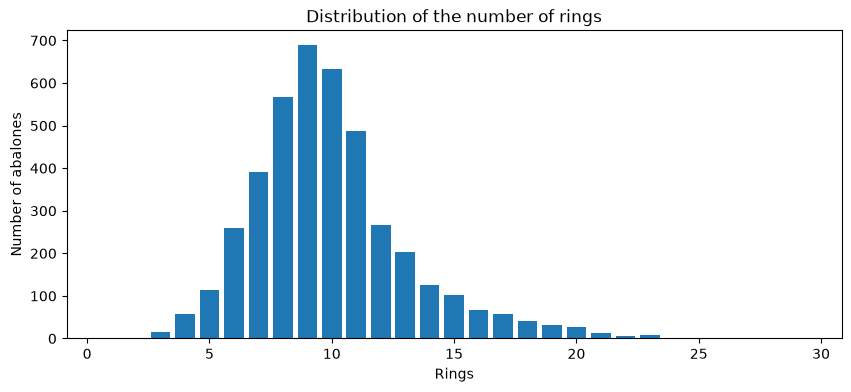

Skewness: 1.11


count    4177.000000
mean        9.933684
std         3.224169
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: Rings, dtype: float64

In [5]:
rings_counts = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(rings_counts.index, rings_counts.values)
ax.set_xlabel(TARGET)
ax.set_ylabel("Number of abalones")
ax.set_title("Distribution of the number of rings")
plt.show()

print(f"Skewness: {df[TARGET].skew():.2f}")
df[TARGET].describe()

The target is concentrated between 7 and 11 rings and has a long right tail (up to 29 rings, skewness ≈ 1.1).
Old abalones are rare, so a model will probably be less accurate on them.

## Categorical feature: `Sex`

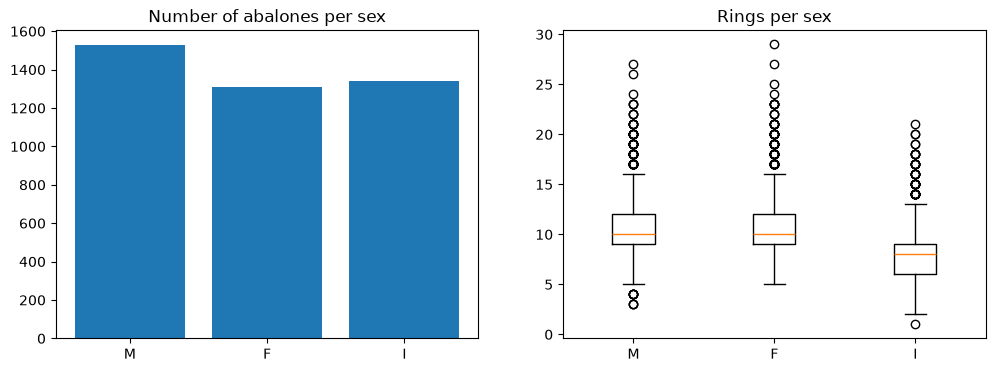

,count,mean,median,std
Sex,,,,
F,1307,11.13,10.0,3.10
I,1342,7.89,8.0,2.51
M,1528,10.71,10.0,3.03


In [6]:
sexes = ["M", "F", "I"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(sexes, df["Sex"].value_counts()[sexes])
axes[0].set_title("Number of abalones per sex")
axes[1].boxplot([df.loc[df["Sex"] == sex, TARGET] for sex in sexes], tick_labels=sexes)
axes[1].set_title("Rings per sex")
plt.show()

df.groupby("Sex")[TARGET].agg(["count", "mean", "median", "std"]).round(2)

`Sex` has three balanced classes: male (M), female (F) and infant (I).
Infants have clearly fewer rings (≈ 7.9 on average) than adults (≈ 10.7 for M, ≈ 11.1 for F),
so this feature is informative and should be one-hot encoded.

## Numerical features

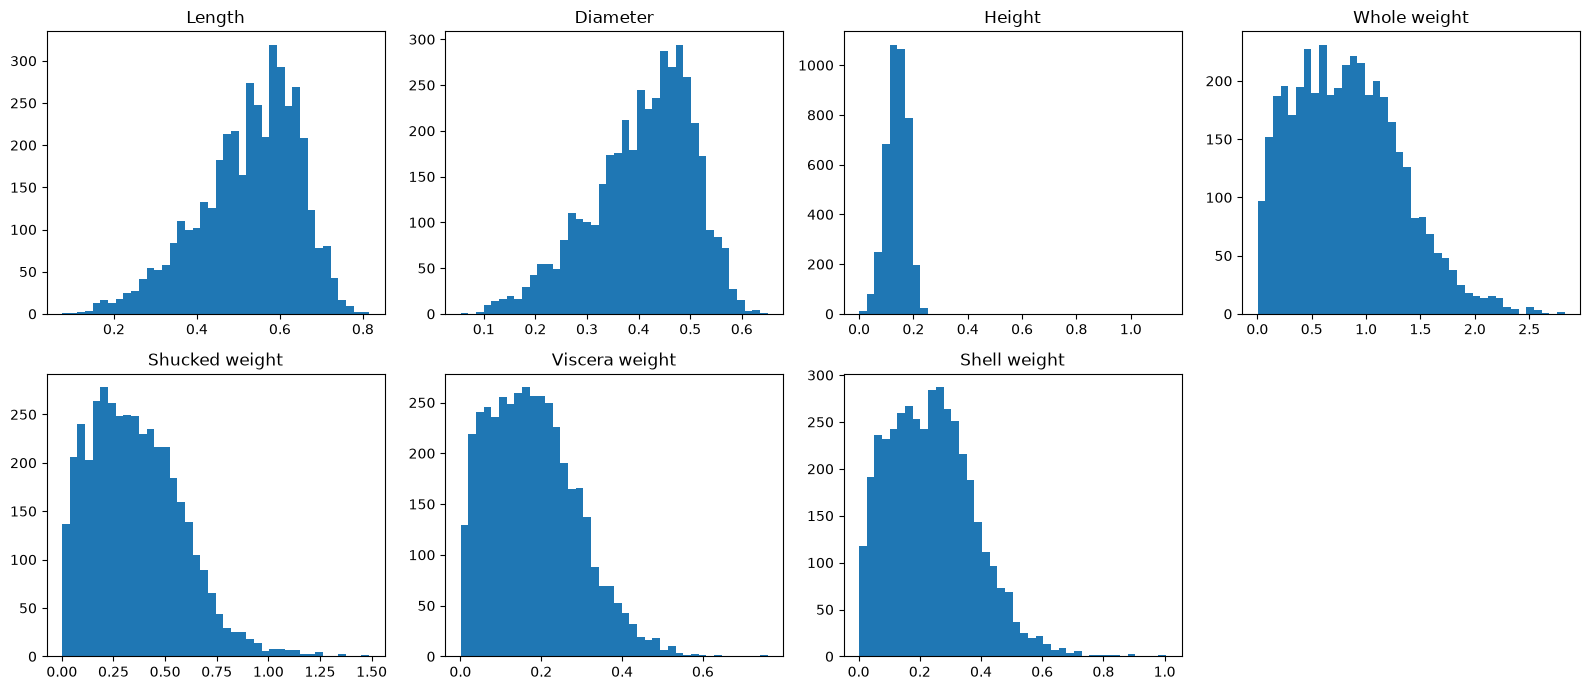

In [7]:
numerical_features = df.select_dtypes("number").columns.drop(TARGET).tolist()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feature in zip(axes.flat, numerical_features):
    ax.hist(df[feature], bins=40)
    ax.set_title(feature)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

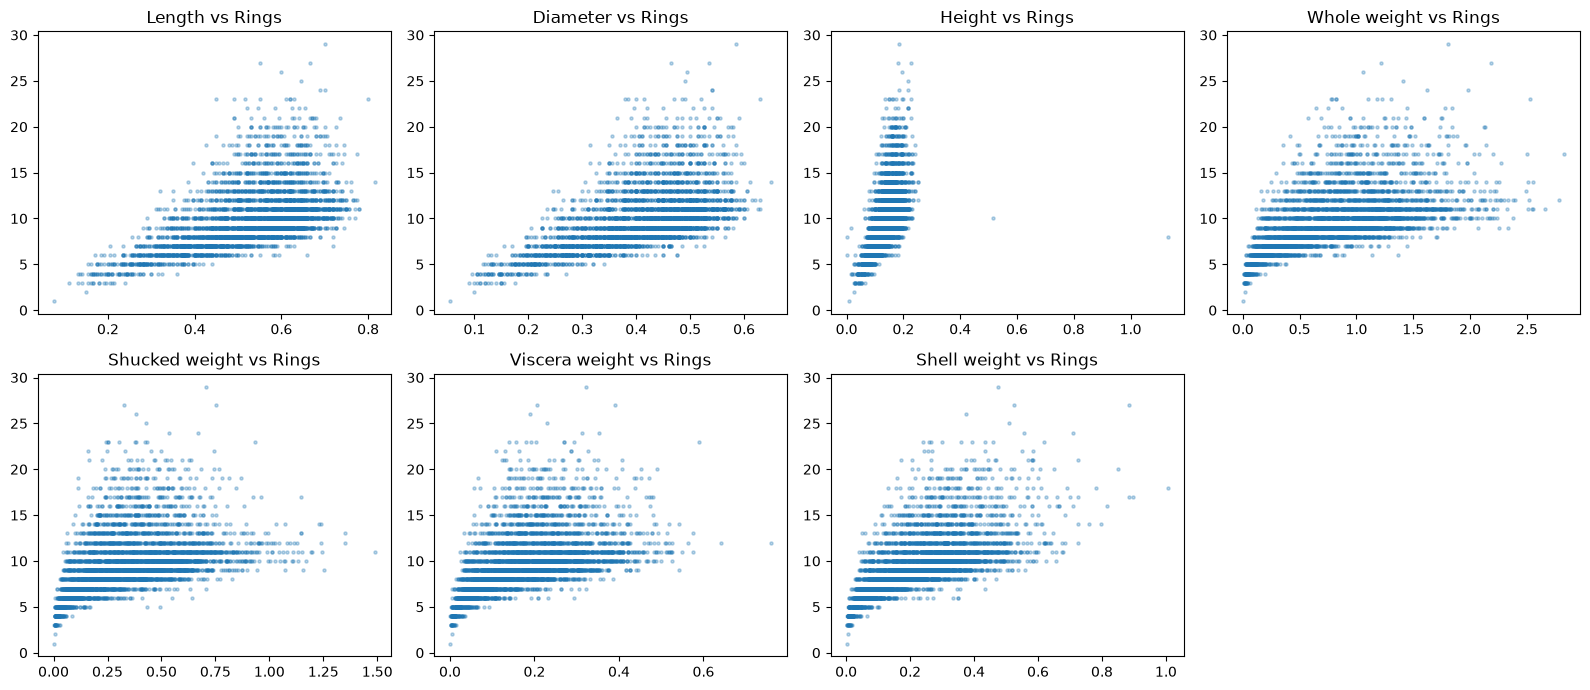

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feature in zip(axes.flat, numerical_features):
    ax.scatter(df[feature], df[TARGET], s=5, alpha=0.3)
    ax.set_title(f"{feature} vs {TARGET}")
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

All measurements grow with the number of rings, but the relation is not linear: the size of an abalone
increases quickly when it is young and then stabilizes, while the number of rings keeps increasing.
The spread of `Rings` also increases with the size, which makes old abalones harder to predict.

## Correlations

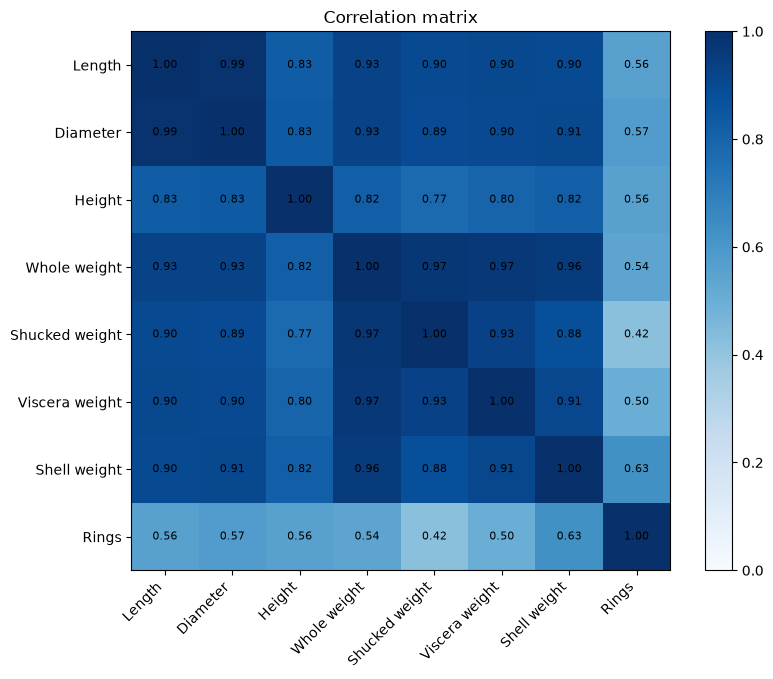

Shell weight      0.627574
Diameter          0.574660
Height            0.557467
Length            0.556720
Whole weight      0.540390
Viscera weight    0.503819
Shucked weight    0.420884
Name: Rings, dtype: float64

In [9]:
corr = df[numerical_features + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image)
ax.set_title("Correlation matrix")
plt.show()

corr[TARGET].drop(TARGET).sort_values(ascending=False)

`Shell weight` is the feature most correlated with `Rings` (0.63), followed by `Diameter`, `Height` and `Length`
(≈ 0.56). The features are extremely correlated with each other (> 0.9 for most pairs), because they all
measure the size of the animal.

## Data quality

In [10]:
print(f"Abalones with a height of 0: {(df['Height'] == 0).sum()}")
print(f"Abalones with a height above 0.4: {(df['Height'] > 0.4).sum()}")

df[(df["Height"] == 0) | (df["Height"] > 0.4)]

Abalones with a height of 0: 2
Abalones with a height above 0.4: 2


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.340,0.000,0.428,0.2065,0.0860,0.1150,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
3996,I,0.315,0.230,0.000,0.134,0.0575,0.0285,0.3505,6


A few rows are clearly erroneous: 2 abalones have a height of 0 and 2 have a height above 0.4
(more than twice the 75th percentile). They will be removed before training.

# Conclusions

- The dataset has 4,177 abalones, 8 features and no missing values or duplicates.
- The target `Rings` is right-skewed (mostly 7 to 11 rings, up to 29): the model will be less accurate on old abalones.
- `Sex` is informative (infants have ~3 fewer rings than adults) and must be one-hot encoded.
- All numerical features are positively correlated with `Rings`, `Shell weight` being the best predictor (0.63).
- The numerical features are highly correlated with each other and their relation with `Rings` is non-linear.
- 4 rows with an impossible height (0 or > 0.4) should be removed.